In [ ]:
import pandas as pd

In [ ]:
print("Python is working!")

In [1]:
print("Hello World")

Hello World


In [4]:

import os

print(os.listdir("/content"))


['.config', 'MyTransaction.csv', 'sample_data']


In [5]:

import pandas as pd

df = pd.read_csv("/content/MyTransaction.csv")

print("Dataset loaded successfully!")
display(df.head())


Dataset loaded successfully!


,Date,Category,RefNo,Withdrawal,Deposit,Balance
0,NaN,NaN,NaN,NaN,NaN,NaN
1,01-01-2023,Rent,3.00E+11,3950.0,0.0,1837.23
2,03-01-2023,Misc,3.00E+11,105.0,0.0,1732.23
3,03-01-2023,Misc,3.37E+11,0.0,55.0,1787.23
4,03-01-2023,Food,3.00E+11,56.0,0.0,1731.23


In [6]:

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove completely empty rows
df = df.dropna(how="all")

# Reset row index
df = df.reset_index(drop=True)

print("\nMissing values after removing empty rows:")
print(df.isnull().sum())

# Display cleaned data
display(df.head())


Missing values before cleaning:
Date          1
Category      1
RefNo         1
Withdrawal    1
Deposit       1
Balance       1
dtype: int64

Missing values after removing empty rows:
Date          0
Category      0
RefNo         0
Withdrawal    0
Deposit       0
Balance       0
dtype: int64


,Date,Category,RefNo,Withdrawal,Deposit,Balance
0,01-01-2023,Rent,3.00E+11,3950.0,0.0,1837.23
1,03-01-2023,Misc,3.00E+11,105.0,0.0,1732.23
2,03-01-2023,Misc,3.37E+11,0.0,55.0,1787.23
3,03-01-2023,Food,3.00E+11,56.0,0.0,1731.23
4,03-01-2023,Misc,3.37E+11,1.0,0.0,1730.23


In [7]:

print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1469 entries, 0 to 1468
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        1469 non-null   object 
 1   Category    1469 non-null   object 
 2   RefNo       1469 non-null   object 
 3   Withdrawal  1469 non-null   float64
 4   Deposit     1469 non-null   float64
 5   Balance     1469 non-null   float64
dtypes: float64(3), object(3)
memory usage: 69.0+ KB
None


In [8]:

# Convert Date column to datetime format
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Check data types
print(df.dtypes)

# Display the first five rows
display(df.head())


Date          datetime64[ns]
Category              object
RefNo                 object
Withdrawal           float64
Deposit              float64
Balance              float64
dtype: object


,Date,Category,RefNo,Withdrawal,Deposit,Balance
0,2023-01-01,Rent,3.00E+11,3950.0,0.0,1837.23
1,2023-01-03,Misc,3.00E+11,105.0,0.0,1732.23
2,2023-01-03,Misc,3.37E+11,0.0,55.0,1787.23
3,2023-01-03,Food,3.00E+11,56.0,0.0,1731.23
4,2023-01-03,Misc,3.37E+11,1.0,0.0,1730.23


In [9]:

# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)


Duplicate rows: 3
Dataset shape after removing duplicates: (1466, 6)


In [10]:

# Total money withdrawn
total_withdrawal = df["Withdrawal"].sum()

# Total money deposited
total_deposit = df["Deposit"].sum()

# Total transactions
total_transactions = len(df)

print("Total Transactions:", total_transactions)
print("Total Withdrawal:", round(total_withdrawal, 2))
print("Total Deposit:", round(total_deposit, 2))


Total Transactions: 1466
Total Withdrawal: 570642.8
Total Deposit: 564928.25


In [11]:

# Total withdrawal by category
category_spending = (
    df.groupby("Category")["Withdrawal"]
    .sum()
    .sort_values(ascending=False)
)

print("Category-wise Spending:")
display(category_spending)


Category-wise Spending:


,Withdrawal
Category,
Misc,459982.44
Food,48253.36
Rent,43804.00
Shopping,13823.00
Transport,4780.00
Salary,0.00


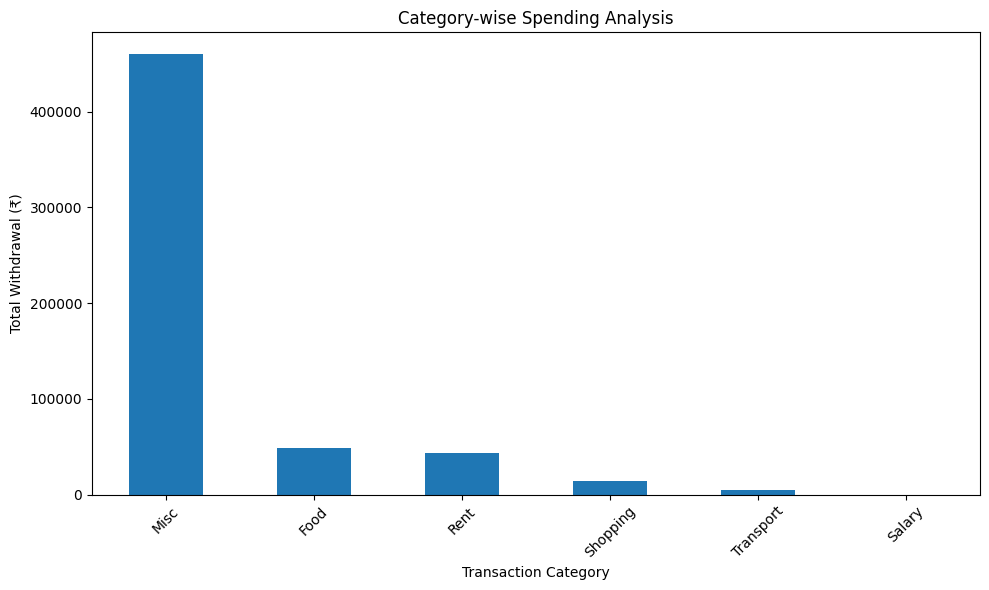

In [12]:

import matplotlib.pyplot as plt

category_spending = df.groupby("Category")["Withdrawal"].sum()
category_spending = category_spending.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
category_spending.plot(kind="bar")

plt.title("Category-wise Spending Analysis")
plt.xlabel("Transaction Category")
plt.ylabel("Total Withdrawal (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [13]:

# Extract month from Date
df["Month"] = df["Date"].dt.month

# Calculate monthly withdrawal
monthly_spending = (
    df.groupby("Month")["Withdrawal"]
    .sum()
)

print("Month-wise Spending:")
display(monthly_spending)


Month-wise Spending:


,Withdrawal
Month,
1,57389.26
2,49666.08
3,43664.95
4,49052.82
5,47822.56
6,57041.11
7,41534.32
8,72871.76
9,54184.30


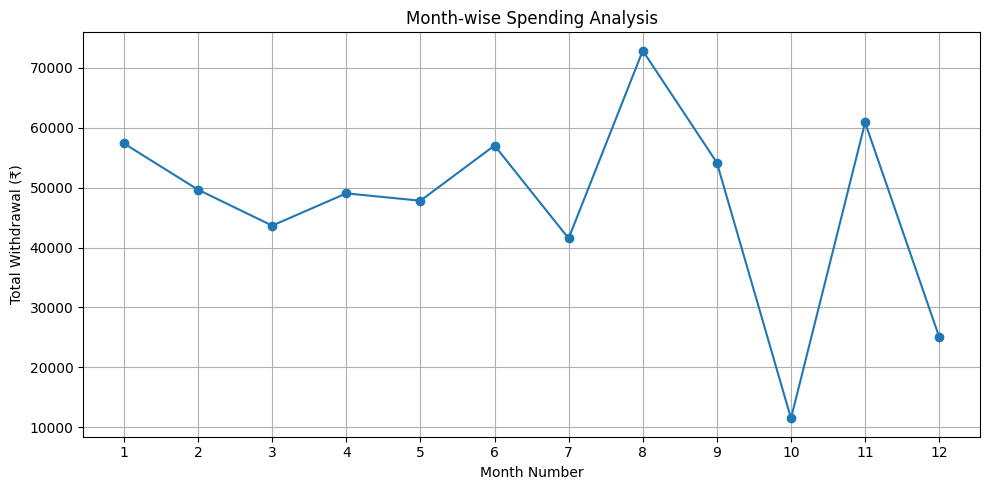

In [14]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

monthly_spending.plot(kind="line", marker="o")

plt.title("Month-wise Spending Analysis")
plt.xlabel("Month Number")
plt.ylabel("Total Withdrawal (₹)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()


In [15]:

# Calculate deposits by category
category_deposit = (
    df.groupby("Category")["Deposit"]
    .sum()
    .sort_values(ascending=False)
)

print("Category-wise Deposit Analysis:")
display(category_deposit)


Category-wise Deposit Analysis:


,Deposit
Category,
Salary,337969.00
Misc,221430.09
Shopping,3372.00
Transport,1718.00
Food,439.16
Rent,0.00


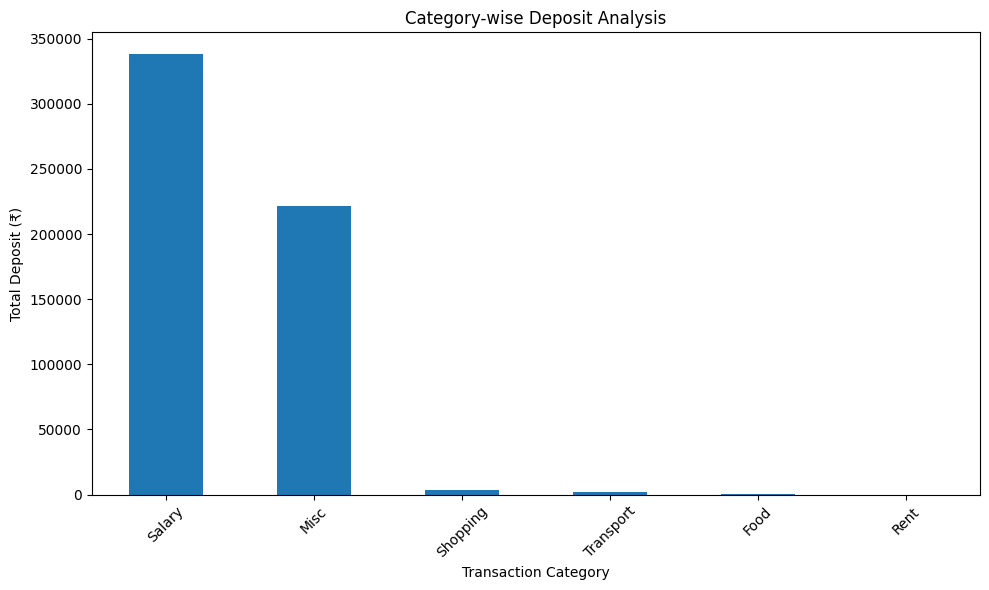

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

category_deposit.plot(kind="bar")

plt.title("Category-wise Deposit Analysis")
plt.xlabel("Transaction Category")
plt.ylabel("Total Deposit (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [17]:

total_withdrawal = df["Withdrawal"].sum()
total_deposit = df["Deposit"].sum()

net_cash_flow = total_deposit - total_withdrawal

print("Total Deposit:", round(total_deposit, 2))
print("Total Withdrawal:", round(total_withdrawal, 2))
print("Net Cash Flow:", round(net_cash_flow, 2))


Total Deposit: 564928.25
Total Withdrawal: 570642.8
Net Cash Flow: -5714.55


In [19]:

# Key Business Insights

total_transactions = len(df)
total_withdrawal = df["Withdrawal"].sum()
total_deposit = df["Deposit"].sum()

category_spending = df.groupby("Category")["Withdrawal"].sum()

highest_spending_category = category_spending.idxmax()
highest_spending_amount = category_spending.max()

print("===== FINTECH TRANSACTION ANALYSIS =====")
print("Total Transactions:", total_transactions)
print("Total Withdrawal:", round(total_withdrawal, 2))
print("Total Deposit:", round(total_deposit, 2))
print("Net Cash Flow:", round(total_deposit - total_withdrawal, 2))

print("\nHighest Spending Category:", highest_spending_category)
print("Highest Spending Amount:", round(highest_spending_amount, 2))


===== FINTECH TRANSACTION ANALYSIS =====
Total Transactions: 1466
Total Withdrawal: 570642.8
Total Deposit: 564928.25
Net Cash Flow: -5714.55

Highest Spending Category: Misc
Highest Spending Amount: 459982.44


In [20]:

# Monthly deposit and withdrawal comparison

monthly_summary = df.groupby(
    df["Date"].dt.to_period("M")
)[["Deposit", "Withdrawal"]].sum()

print("Monthly Deposit vs Withdrawal:")
display(monthly_summary)


Monthly Deposit vs Withdrawal:


,Deposit,Withdrawal
Date,,
2023-01,63292.00,57389.26
2023-02,49906.00,49666.08
2023-03,44821.00,43664.95
2023-04,48428.40,49052.82
2023-05,43846.00,47822.56
2023-06,49615.00,57041.11
2023-07,48030.09,41534.32
2023-08,77697.00,72871.76
2023-09,43668.76,54184.30


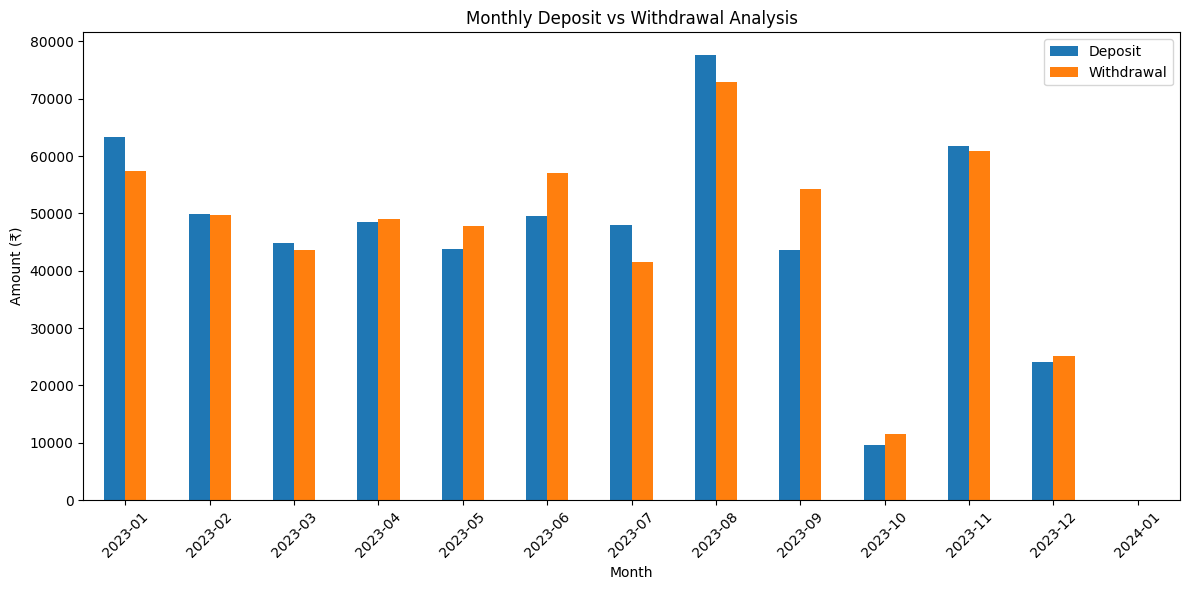

In [21]:

import matplotlib.pyplot as plt

monthly_summary.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Monthly Deposit vs Withdrawal Analysis")
plt.xlabel("Month")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=45)
plt.legend(["Deposit", "Withdrawal"])
plt.tight_layout()
plt.show()


In [22]:

# Export cleaned dataset
df.to_csv("Cleaned_MyTransaction.csv", index=False)

print("Cleaned dataset exported successfully!")


Cleaned dataset exported successfully!


In [23]:

from google.colab import files

files.download("Cleaned_MyTransaction.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>